### IPD440 - APRENDIZAJE DE MAQUINAS
# Clase 9: Building Basic Neural Nets
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.datasets import make_blobs, make_moons
from matplotlib.colors import ListedColormap
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
cm = plt.cm.coolwarm
cm_bright = ListedColormap(['dodgerblue', 'tomato'])

# Datos linealmente separables

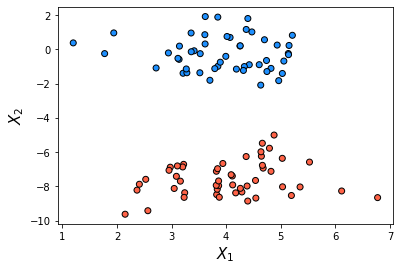

In [3]:
X, y = make_blobs(random_state=754, cluster_std=1, centers=2)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright, ec="k")
plt.xlabel("$X_1$",fontsize=15)
plt.ylabel("$X_2$",fontsize=15)
plt.show()

## Modelo secuencial

El modelo secuencial tiene capas apiladas con exactamente un tensor de entrada y un tensor de salida.

No es apropiado cuando: 
- tiene múltiples entradas o múltiples salidas 
- cualquiera de sus capas tiene múltiples entradas o múltiples salidas
- necesita compartir capas 
- quiere una topología no lineal

In [4]:
from keras.models import Sequential

In [5]:
slp = Sequential()

## Capas

- Las capas son los componentes básicos de las redes neuronales. 
- Los elementos principales de una capa son: 
    - el número de neuronas 
    - la función de activación
- Además, hay distintos tipos de capas: densas, convolucionales, recurrentes, de atención, etc.

### Capa Densa

En una capa **densa** (`Dense`), también conocida como Fully Connected (FC), cada neurona recibe como entrada el resultado de todas las neuronas de la capa previa y su salida es la multiplicación de los pesos por la entrada.

<div align="center">
    <img src="img/fclayer.png" alt="" width="20%" align="center" />
</div>

In [6]:
from keras.layers import Dense

En Keras no agregamos capas correspondientes a los nodos de entrada, solo lo hacemos para los nodos ocultos y de salida. Nuestro primer modelo será un Perceptrón, por lo tanto, no tenemos capas ocultas, los nodos de entrada están conectados directamente al nodo de salida. Sin embargo, la primera capa en los modelos Keras necesita conocer las dimensiones del input. En este caso, la dimensionalidad de entrada es 2 porque tenemos 2 características, las coordenadas $X_1$ y $X_2$ de los puntos que trazamos arriba, por lo que tenemos 2 nodos de entrada. Simplemente puede pensar en ello como un vector de 2 números.

In [7]:
slp.add(Dense(units=1, input_shape=(2,), activation='sigmoid'))

In [8]:
from keras.utils import plot_model

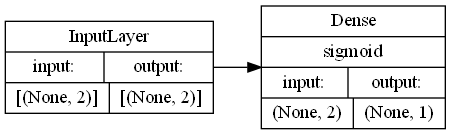

In [9]:
plot_model(slp, to_file='model_plot.png', show_shapes=True, show_layer_names=False, rankdir="LR",show_layer_activations=True)

In [10]:
slp.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 1)                 3         
                                                                 
Total params: 3 (12.00 Byte)
Trainable params: 3 (12.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


### El rol del sesgo en una capa neuronal

El sesgo de una capa es un valor constante (no depende de lo que hayan procesado las capas anteriores) que se incorpora a una capa con el objetivo de darle flexibilidad a los valores posibles del output de la capa.

¿Por qué es necesario? Considere esta red de 1-input y 1-output que no tiene sesgo:

<div align="center">
    <img src="img/unbias.gif" alt="" width="20%" align="center" />
</div>

La salida de la red se calcula multiplicando la entrada ($x$) por el peso ($w_0$) y pasando el resultado a través de algún tipo de función de activación (por ejemplo, sigmoid).

Aquí está la función que calcula esta red, para diferentes valores de $w_0$:

<div align="center">
    <img src="img/pesos.png" alt="" width="30%" align="center" />
</div>

Cambiar el peso $w_0$ esencialmente cambia la "inclinación" del sigmoide. Eso es útil, pero ¿qué pasaría si quisiera desplazar toda la curva hacia la derecha?. Eso es exactamente lo que el sesgo permite hacer.

Si agregamos un sesgo a esa red, entonces la salida de la red se convierte en $sig(w_0*x + w_1*1.0)$:

<div align="center">
    <img src="img/bias.gif" alt="" width="20%" align="center" />
</div>

Por lo tanto, el output, para diferentes valores de $w_1$:

<div align="center">
    <img src="img/sesgos.png" alt="" width="30%" align="center" />
</div>

#### Sesgo

Finalmente, podemos concluir que es importante el sesgo de una capa porque le permite al output de esa capa llegar a condiciones que pueden ser necesarias para el problema.

- Los pesos controlan la inclinación/pendiente de la curva.
- Los sesgos controlan la traslación del output.

## Compilación

El método `compile` configura el modelo para entrenamiento. Lo más importante es indicar el optimizador, la función de pérdida (loss) y las métricas de evaluación.

### Optimizadores

- `SGD` es el tradicional descenso de gradiente. Ventaja: generaliza bien.
- `Adam` es computacionalmente eficiente, requiere poca memoria y es adecuado para problemas que son grandes en términos de datos/parámetros. Ventaja: converge más rápido y con la configuración adecuada ha demostrado mejores resultados que SGD.
- `RMSprop` es una técnica de optimización basada en gradientes, pero utiliza una tasa de aprendizaje adaptable en lugar de tratarla como hiperparámetro, por lo tanto, cambia con el tiempo. Ventajas: robusto y converge rápido. 
- etc.

### Loss

El propósito de las funciones de pérdida es cuantificar lo que un modelo debería tratar de minimizar durante el entrenamiento.

#### Regression losses

- ```loss = mean(square(y_true - y_pred))```. El error cuadrático medio, o **MSE**, es la función más utilizada para problemas de regresión si la distribución de la variable objetivo es gaussiana. 

- ```loss = mean(abs(y_true - y_pred))```. En presencia de outliers, se recomienda el error absoluto medio, o **MAE**, porque es más robusto. 

#### Probabilistic losses

- **Binary Cross-Entropy** es la función predeterminada en problemas de clasificación binaria donde los valores objetivo son 0 o 1, y mide la diferencia promedio entre la distribución de clase real y predicha.
    - `y_true` (etiqueta verdadera): es 0 o 1. 
    - `y_pred` (valor predicho): esta es la predicción del modelo, es decir, un único flotante que representa un logit (entre [-inf, inf]) o una probabilidad (entre [0., 1.]).

- **Categorical Cross-Entropy** se usa cuando se tienen dos o más clases. Requiere que las etiquetas tengan representación `one_hot` (Por ejemplo: `y_true = [[0, 1, 0], [0, 0, 1]]`).

- **Sparse Categorical Cross-Entropy** se usa cuando se trabaja con etiquetas como números enteros (Por ejemplo: `y_true = [1, 2]`).

### Métricas

#### Regression metrics
Las más comunes son MSE, MAE, etc.

#### Accuracy metrics
La más común es **Accuracy**.

#### Classification metrics
Las más comunes son Precision, Recall, etc.

### ¿ Loss == Métrica ?

La función de pérdida (Loss) no evalúa el desempeño de su modelo, se utiliza durante el proceso de aprendizaje para medir si se está optimizando correctamente.

Las métricas de evaluación se usan para juzgar el desempeño general del modelo. Aunque pueden ser similares a las funciones de pérdida, los resultados de la evaluación de una métrica no se utilizan al entrenar el modelo.

In [11]:
slp.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])

## Entrenamiento

El método `fit` entrena el modelo para un número fijo de épocas (iteraciones).

In [12]:
slp_history = slp.fit(X, y, verbose=0, epochs=100)

In [13]:
def plot_model_accuracy(history):
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['loss'])
    plt.title('model accuracy')
    plt.ylabel('accuracy')
    plt.xlabel('epoch')
    plt.legend(['accuracy', 'loss'], loc='best')
    plt.show()

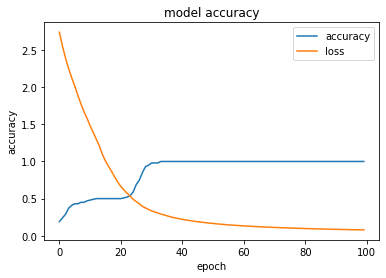

In [14]:
plot_model_accuracy(slp_history)

In [15]:
def plot_decision_boundary(model, X, y):
    if len(set(y)) == 2:
        amin, bmin = X.min(axis=0) - 0.1
        amax, bmax = X.max(axis=0) + 0.1
        hticks = np.linspace(amin, amax, 101)
        vticks = np.linspace(bmin, bmax, 101)

        aa, bb = np.meshgrid(hticks, vticks)
        ab = np.c_[aa.ravel(), bb.ravel()]
        c = model.predict(ab, verbose=False)
        cc = c.reshape(aa.shape)

        cm = plt.cm.coolwarm
        cm_bright = ListedColormap(['dodgerblue', 'tomato'])

        fig, ax = plt.subplots()
        contour = plt.contourf(aa, bb, cc, cmap=cm, alpha=0.6)

        ax_c = fig.colorbar(contour)
        ax_c.set_label("$P(y = 1)$")
        ax_c.set_ticks([0, 0.25, 0.5, 0.75, 1])

        plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm_bright, ec="k")
        plt.title(f"Accuracy: {round(accuracy_score(y, np.round(model.predict(X, verbose=False)).astype(int)),2)}")

        plt.xlim(amin, amax)
        plt.ylim(bmin, bmax)
        plt.show()
    else:
        x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
        y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, 101), np.linspace(y_min, y_max, 101))

        Z = model.predict(np.c_[xx.ravel(), yy.ravel()], verbose=False)
        Z = np.argmax(Z, axis=1)
        Z = Z.reshape(xx.shape)
        fig = plt.figure()
        plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
        
        plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, ec="k")
        plt.title(f"Accuracy: {round(accuracy_score(y, np.argmax(model.predict(X, verbose=False), axis=1)),2)}")
        
        plt.xlim(xx.min(), xx.max())
        plt.ylim(yy.min(), yy.max())
        plt.show()

## Frontera de decisión

Separa las clases dependiendo del modelo y su función de activación.

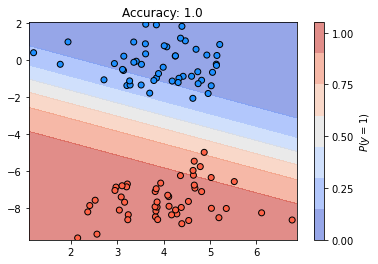

In [16]:
plot_decision_boundary(slp,X,y)

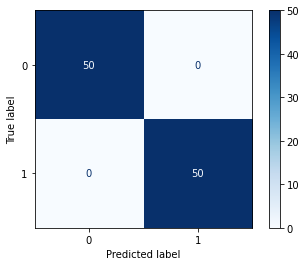

In [17]:
y_pred = np.round(slp.predict(X, verbose=False)).astype(int)

cm = confusion_matrix(y, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.show()

# Datos que no son linealmente separables

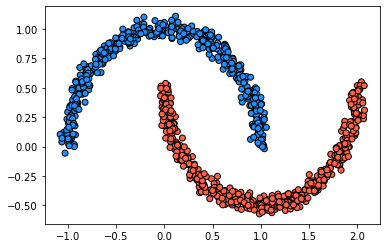

In [18]:
X_moons, y_moons = make_moons(n_samples=1000, random_state=27, noise=0.04)
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap=cm_bright, ec="k")
plt.show()

In [19]:
slp_moons = Sequential()

In [20]:
slp_moons.add(Dense(units=1, input_shape=(2,), activation='sigmoid'))

In [21]:
slp_moons.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])

In [22]:
slp_moons_history = slp_moons.fit(X_moons, y_moons, verbose=0, epochs=100)

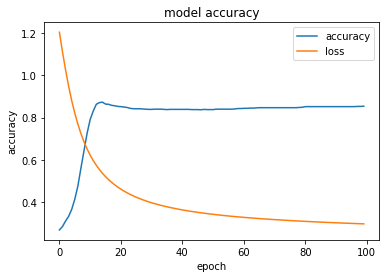

In [23]:
plot_model_accuracy(slp_moons_history)

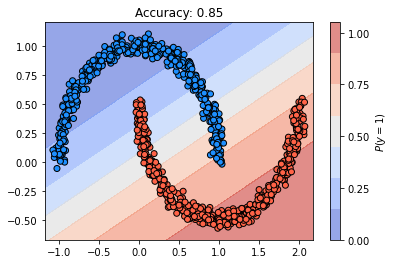

In [24]:
plot_decision_boundary(slp_moons,X_moons,y_moons)

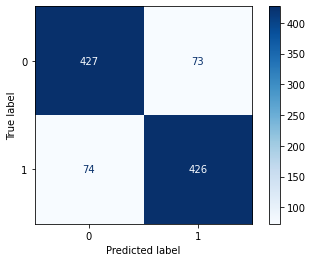

In [25]:
y_pred = np.round(slp_moons.predict(X_moons, verbose=False)).astype(int)

cm = confusion_matrix(y_moons, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.show()

## Capas ocultas

Las redes neuronales profundas escapan de las limitaciones lineales del perceptrón mediante la concatenación de sucesivas capas con función de activación no lineal.

In [26]:
mlp = Sequential()

In [27]:
# Hidden layers
mlp.add(Dense(8, input_shape=(2,), activation='tanh'))
mlp.add(Dense(4, activation='tanh'))
mlp.add(Dense(2, activation='tanh'))

# Output layer
mlp.add(Dense(1, activation='sigmoid'))

In [28]:
mlp.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_2 (Dense)             (None, 8)                 24        
                                                                 
 dense_3 (Dense)             (None, 4)                 36        
                                                                 
 dense_4 (Dense)             (None, 2)                 10        
                                                                 
 dense_5 (Dense)             (None, 1)                 3         
                                                                 
Total params: 73 (292.00 Byte)
Trainable params: 73 (292.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [29]:
mlp.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])

In [30]:
mlp_history = mlp.fit(X_moons, y_moons, verbose=0, epochs=300)

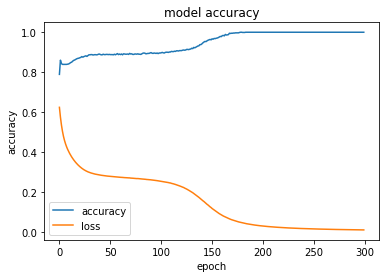

In [31]:
plot_model_accuracy(mlp_history)

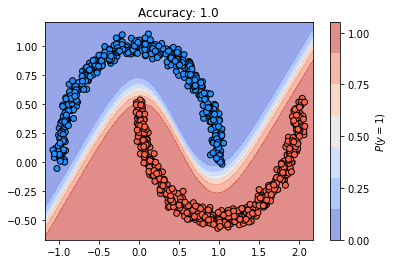

In [32]:
plot_decision_boundary(mlp,X_moons,y_moons)

32/32 [==============================] - 0s 1ms/step


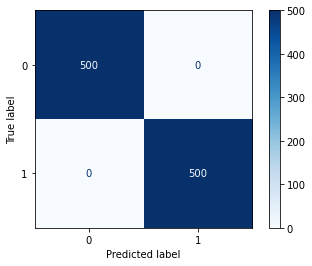

In [33]:
y_pred = np.round(mlp.predict(X_moons)).astype(int)

cm = confusion_matrix(y_moons, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.show()

# Clasificación Multi-Clase

In [34]:
dfIris = sns.load_dataset("iris")

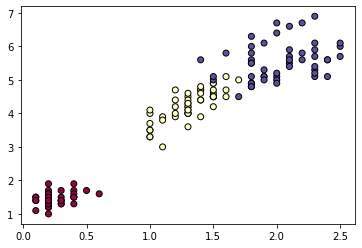

In [35]:
X = dfIris[['petal_width','petal_length']].to_numpy()
y = dfIris.species
codes = {'setosa':0, 'versicolor':1, 'virginica':2}
y_cat = y.map(codes)
plt.scatter(X[:, 0], X[:, 1], c=y_cat, ec="k", cmap=plt.cm.Spectral)
plt.show()

In [36]:
model = Sequential()

In [37]:
model.add(Dense(128, input_shape=(2,), activation='tanh'))

In [38]:
model.add(Dense(64, activation='tanh'))
model.add(Dense(32, activation='tanh'))
model.add(Dense(16, activation='tanh'))

In [39]:
model.add(Dense(3, activation='softmax'))

#### One-hot Encoding


In [40]:
from keras.utils import to_categorical

In [41]:
to_categorical([0, 1, 2, 1], num_classes=3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 1., 0.]], dtype=float32)

In [42]:
model.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

In [43]:
history = model.fit(X, to_categorical(y_cat), verbose=0, epochs=300)

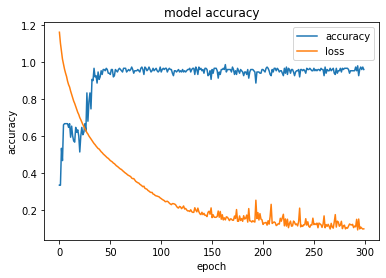

In [44]:
plot_model_accuracy(history)

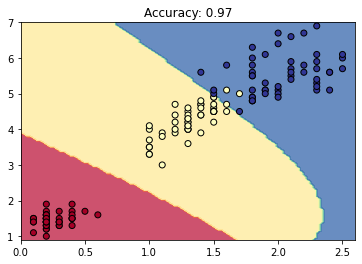

In [45]:
plot_decision_boundary(model,X,y_cat)

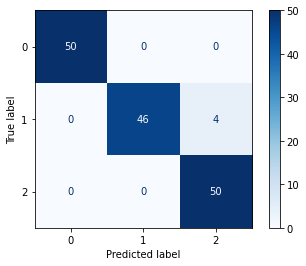

In [46]:
y_pred = np.argmax(model.predict(X, verbose=False), axis=1)

cm = confusion_matrix(y_cat, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.show()

# Clasificación de imágenes

## MNIST

In [47]:
from keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

In [48]:
train_images.shape

(60000, 28, 28)

In [49]:
test_images.shape

(10000, 28, 28)

In [50]:
test_labels.shape

(10000,)

In [51]:
network = Sequential()
network.add(Dense(128, activation='relu', input_shape=(28 * 28,)))
network.add(Dense(10, activation='softmax'))

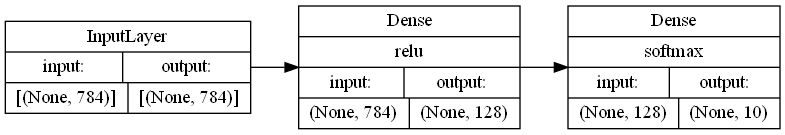

In [52]:
plot_model(network, to_file='model_plot.png', show_shapes=True, show_layer_names=False, rankdir="LR",show_layer_activations=True)

### Modelo

<div align="center">
    <img src="img/mnist.png" alt="" width="50%" align="center" />
</div>

In [53]:
network.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_11 (Dense)            (None, 128)               100480    
                                                                 
 dense_12 (Dense)            (None, 10)                1290      
                                                                 
Total params: 101770 (397.54 KB)
Trainable params: 101770 (397.54 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [54]:
network.compile(optimizer='rmsprop', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

#### Normalización y Reshaping

In [55]:
train_images = train_images.reshape((60000, 28 * 28))
train_images = train_images.astype('float32') / 255
test_images = test_images.reshape((10000, 28 * 28))
test_images = test_images.astype('float32') / 255

In [56]:
train_images.shape

(60000, 784)

In [57]:
history = network.fit(train_images, train_labels, epochs=5, batch_size=64)

Epoch 1/5
938/938 [==============================] - 2s 2ms/step - loss: 0.2896 - accuracy: 0.9194
Epoch 2/5
938/938 [==============================] - 2s 2ms/step - loss: 0.1351 - accuracy: 0.9609
Epoch 3/5
938/938 [==============================] - 2s 2ms/step - loss: 0.0951 - accuracy: 0.9719
Epoch 4/5
938/938 [==============================] - 2s 2ms/step - loss: 0.0741 - accuracy: 0.9781
Epoch 5/5
938/938 [==============================] - 2s 2ms/step - loss: 0.0600 - accuracy: 0.9824


In [58]:
test_loss, test_acc = network.evaluate(test_images, test_labels, verbose=0)
print('test_loss:', test_loss)
print('test_acc:', test_acc)

test_loss: 0.0785515233874321
test_acc: 0.9749000072479248


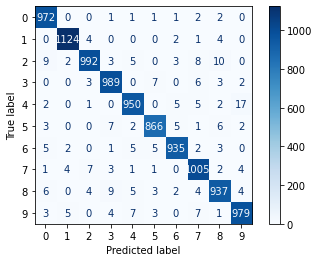

In [59]:
y_pred = np.argmax(network.predict(test_images, verbose=False), axis=1)
cm = confusion_matrix(test_labels, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.show()